# 02 · Training both models (on IBM LinuxONE)
Same functions as `python -m claimsense.training`. Writes to `shared/models_notebook` so the running service is not touched.

In [1]:
import sys, os, platform, subprocess
sys.path.insert(0, os.path.expanduser("~/claimsense/src"))
import xgboost  # before torch (see training.py)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SHARED = os.path.expanduser("~/shared")
RAW = f"{SHARED}/data/raw"
print(platform.machine(), platform.platform())
print(subprocess.run("grep -E '^Type' /proc/sysinfo; lscpu | grep -io nnpa | head -1", shell=True, capture_output=True, text=True).stdout)

s390x Linux-6.8.0-147-generic-s390x-with-glibc2.39
Type:                 9175
Type 1 Percentage:    0
Type 2 Percentage:    0
Type 3 Percentage:    0
Type 4 Percentage:    0
Type 5 Percentage:    0
nnpa



In [2]:
import json, time
from pathlib import Path
from claimsense import training as T
t = time.time()
claims, bene, splits, ctx, feats = T.prepare(RAW)
print(f"features for {len(claims):,} claims in {time.time()-t:.1f}s")
splits.groupby("split").label.agg(["size", "sum"])

features for 558,211 claims in 12.1s


,size,sum
split,,
test,811,76
train,3787,354
val,812,76


## Provider model: XGBoost on rolling provider aggregates
Trained on each training provider's history at 25/50/75/100% so it can score providers whose history is still filling up in the live stream.

In [3]:
pmodel, meta, pmetrics = T.train_provider_model(claims, feats, ctx)
pd.DataFrame(pmetrics).T.round(3)

,n,positives,pr_auc,roc_auc,precision_top5pct,recall_top5pct,base_rate
val_history25,812.0,76.0,0.670,0.927,0.805,0.434,0.094
val_history100,812.0,76.0,0.726,0.944,0.732,0.395,0.094
test_history25,811.0,76.0,0.655,0.928,0.780,0.421,0.094
test_history100,811.0,76.0,0.675,0.942,0.732,0.395,0.094


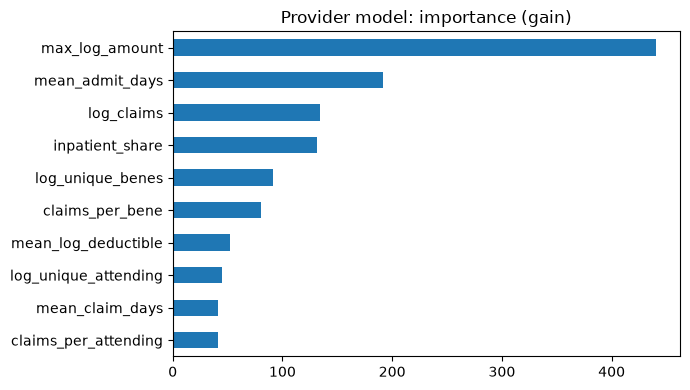

In [4]:
imp = pd.Series(meta["importance_gain"]).sort_values()
imp.tail(10).plot.barh(figsize=(7, 4), title="Provider model: importance (gain)"); plt.tight_layout()

## Claim model: PyTorch autoencoder, trained on claims from non-flagged providers only

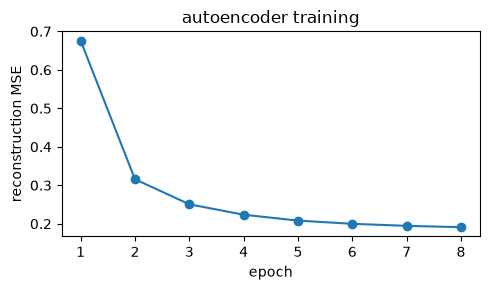

In [5]:
ae, scaler, history = T.train_autoencoder(claims, feats, epochs=8)
plt.figure(figsize=(5, 3)); plt.plot(range(1, len(history) + 1), history, "o-"); plt.xlabel("epoch"); plt.ylabel("reconstruction MSE"); plt.title("autoencoder training"); plt.tight_layout()

threshold (99th pct of clean validation claims) = 2.958; test flag rate = 0.95%


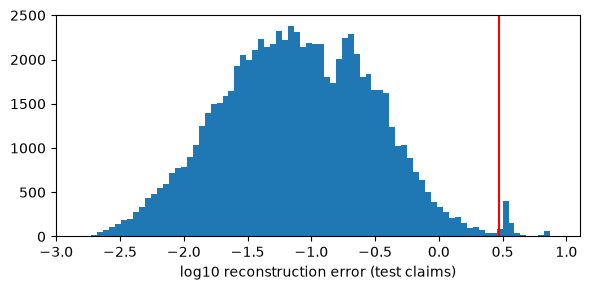

In [6]:
val_clean = ((claims.split == "val") & (claims.label == 0)).values
err_val, _ = T.reconstruction_errors(ae, scaler, feats.values[val_clean])
threshold = float(np.quantile(err_val, 0.99))
test = (claims.split == "test").values
err_test, per_feature = T.reconstruction_errors(ae, scaler, feats.values[test])
print(f"threshold (99th pct of clean validation claims) = {threshold:.3f}; test flag rate = {(err_test >= threshold).mean():.2%}")
plt.figure(figsize=(6, 3)); plt.hist(np.log10(err_test + 1e-6), bins=80); plt.axvline(np.log10(threshold), color="r"); plt.xlabel("log10 reconstruction error (test claims)"); plt.tight_layout()

## Run the autoencoder on the Telum II on-chip AI accelerator
`torch_nnpa` registers an `nnpa` device: moving the model there is one line.

In [7]:
import torch, torch_nnpa, copy
print("NNPA available:", torch_nnpa.NNPAModule.is_available(), "| Telum II:", torch_nnpa.NNPAModule.is_telum2_available())
dev = torch_nnpa.device()
ae_nnpa = copy.deepcopy(ae).to(dev).eval()
Z = torch.from_numpy(scaler.transform(feats.values[test][:4096]))
with torch.no_grad():
    cpu_out = ae(Z); nnpa_out = ae_nnpa(Z.to(dev)).cpu()
print("max |cpu - nnpa| =", float((cpu_out - nnpa_out).abs().max()))
for name, fn in [("cpu", lambda: ae(Z)), ("nnpa", lambda: ae_nnpa(Z.to(dev)).cpu())]:
    with torch.no_grad():
        for _ in range(20): fn()
        t = time.perf_counter(); [fn() for _ in range(200)]; dt = (time.perf_counter() - t) / 200
    print(f"{name}: {dt*1e6:.0f} µs per 4096-claim batch -> {4096/dt:,.0f} claims/s")

NNPA available: True | Telum II: True
max |cpu - nnpa| = 0.08969557285308838


cpu: 1581 µs per 4096-claim batch -> 2,590,309 claims/s


nnpa: 1190 µs per 4096-claim batch -> 3,443,002 claims/s


## Thresholds tuned on the validation stream (replayed through the real scoring engine)
See `shared/data/hold_curve_val.csv` from the production training run:

{'anomaly_threshold': 2.957554340362549,
 'provider_threshold': 0.56,
 'min_provider_claims': 10,
 'hold_cap': 0.02,
 'min_hold_precision_val': 0.7}

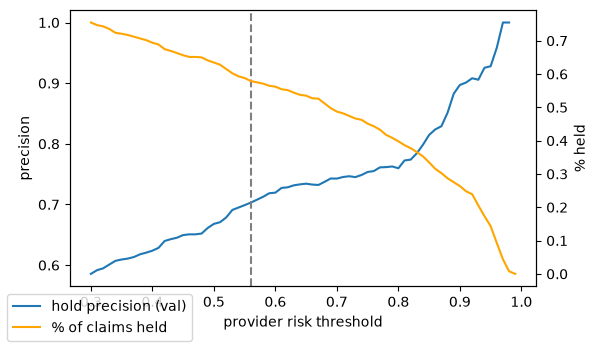

In [8]:
curve = pd.read_csv(f"{SHARED}/data/hold_curve_val.csv")
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(curve.threshold, curve.precision, label="hold precision (val)"); ax2 = ax.twinx(); ax2.plot(curve.threshold, curve.hold_share * 100, color="orange", label="% of claims held")
thr = json.load(open(f"{SHARED}/models/thresholds.json")); ax.axvline(thr["provider_threshold"], color="gray", ls="--")
ax.set_xlabel("provider risk threshold"); ax.set_ylabel("precision"); ax2.set_ylabel("% held"); fig.legend(loc="lower left"); plt.tight_layout()
thr

In [9]:
m = json.load(open(f"{SHARED}/models/metrics.json"))
pd.DataFrame({"validation": m["decisions_val"], "test": m["decisions_test"]})

,validation,test
claims,77383,78594
mix,"{'PAY': 0.987, 'RETURN_WITH_FIX': 0.0072, 'HOL...","{'PAY': 0.9878, 'RETURN_WITH_FIX': 0.0073, 'HO..."
hold_precision_flagged_provider,0.703125,0.613811
return_share_from_flagged_provider,0.110714,0.126316
dollars_held,1331850.0,1265680.0
base_rate_flagged_provider_claims,0.358903,0.361542
